# DEFT2013 Task 2:
ALI Mhammad Nour





In [ ]:
!pip install fasttext

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.4/73.4 kB 4.7 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Using cached pybind11-3.0.2-py3-none-any.whl.metadata (10 kB)
Using cached pybind11-3.0.2-py3-none-any.whl (310 kB)
  Created wheel for fasttext: filename=fasttext-0.9.3-cp312-cp312-linux_x86_64.whl size=4647416 sha256=fd8de3b70aa55608289e305b2a205c494f4bd2091551e71f73241ef14ed6e0f1
  Stored in directory: /root/.cache/pip/wheels/20/27/95/a7baf1b435f1cbde017cabdf1e9688526d2b0e929255a359c6
Successfully built fasttext


In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score
from sklearn.metrics import f1_score
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd

df_train = pd.read_csv('/content/drive/MyDrive/Nantes/NLP/Projet au TALN/train.csv')
df_test = pd.read_csv('/content/drive/MyDrive/Nantes/NLP/Projet au TALN/test.csv')

# 1. Data Exploration

In [ ]:
print(df_train.columns)

Index(['doc_id', 'titre', 'type', 'difficulte', 'cout', 'ingredients',
       'recette'],
      dtype='object')


In [ ]:

df_train.head()

,doc_id,titre,type,difficulte,cout,ingredients,recette
0,recette_221358.xml,"Feuilleté de saumon et de poireau, sauce aux c...",Plat principal,Facile,Moyen,- 1 gros pavé de saumon - 100 g de crevettes d...,Couper finement le blanc et un peu de vert des...
1,recette_48656.xml,Cake poulet/moutarde/amandes,Entrée,Très facile,Bon marché,- 3 œufs - 150 g de farine - 1 sachet de levur...,"Couper finement l'échalote, la faire revenir à..."
2,recette_30049.xml,Bûche à la truite fumée (7ème rencontre),Entrée,Moyennement difficile,Assez Cher,- 800 g de filet de truite saumonnée fumée en ...,Faites blanchir les épinards à l'eau bouillant...
3,recette_71424.xml,Gâteau au yaourt au coco sans huile de laetitia,Dessert,Très facile,Bon marché,- 1 pot de yaourt - 1 pot de lait de coco - 3 ...,Mélanger dans l'ordre tous les ingrédients en ...
4,recette_217204.xml,Crêpes au canard laqué,Entrée,Moyennement difficile,Moyen,- 90 g de farine - 45 g de maïzena - 2 œufs - ...,"Fouetter les œufs avec l'eau, le lait et le su..."


## 1.1 Corpus Statistics


In [ ]:
print(df_train.shape)
print(df_test.shape)

(12473, 7)
(1388, 7)



Train set: 12 473 documents

Test set: 1 388 documents

Total: 13 861 recettes

The dataset follows approximately a 90/10 train-test split.

## 1.2 Class Distribution

In [ ]:
df_train['type'].value_counts()

,count
type,
Plat principal,5802
Dessert,3762
Entrée,2909


In [ ]:
df_train['type'].value_counts(normalize=True) * 100

,proportion
type,
Plat principal,46.516476
Dessert,30.161148
Entrée,23.322376


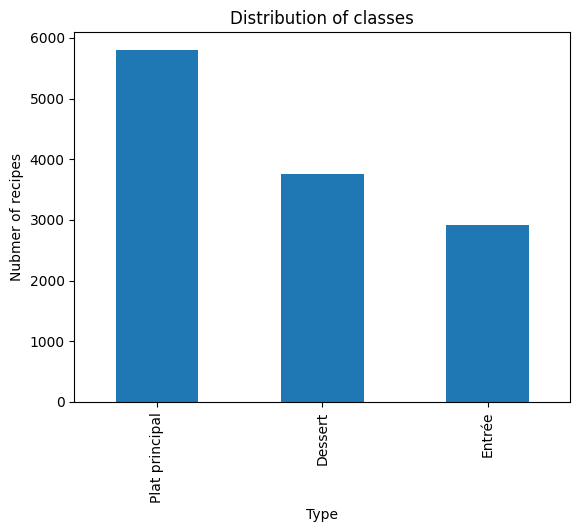

In [ ]:
import matplotlib.pyplot as plt

df_train['type'].value_counts().plot(kind='bar')

plt.title('Distribution of classes')
plt.xlabel('Type')
plt.ylabel('Nubmer of recipes')

plt.show()


Distribution of the **Type** class in the training data:

| Type | Number | Percent
|-----|------| -----|
| Entrée | 5802 | 46.5% |
| Plat principal | 3762 | 30.2% |
| Dessert | 2909 | 23.3% |

The dataset shows a moderate class imbalance. The class **Entrée** is the most frequent (≈***46%***), while Dessert is the least represented (≈***23%***).
This imbalance should be considered when evaluating models, particularly when using **Macro-F1**, which gives equal importance to each class.

## 1.3 Text Length Analysis

In [ ]:

df_train['titre_len'] = df_train['titre'].str.split().str.len()

In [ ]:
df_train["titre_len"].describe()

,titre_len
count,12473.000000
mean,5.127074
std,2.061778
min,1.000000
25%,4.000000
50%,5.000000
75%,6.000000
max,21.000000


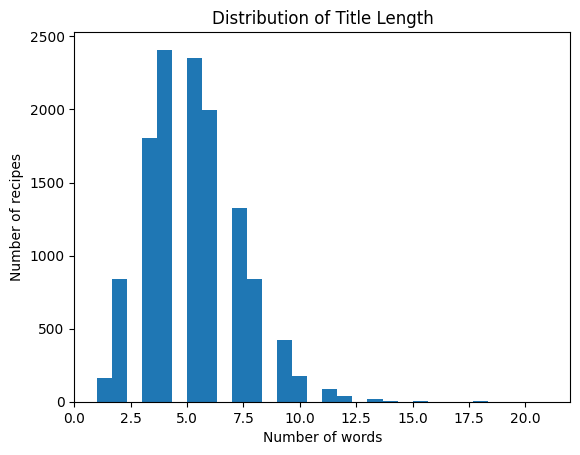

In [ ]:
plt.hist(df_train["titre_len"], bins=30)
plt.title("Distribution of Title Length")
plt.xlabel("Number of words")
plt.ylabel("Number of recipes")
plt.show()

**Title Length**

| Statistic | Value
|-----|------|
| Mean | 5.13 words |
| Median | 5 words |
| Minimum | 1 word |
| Maximum | 21 word |

Recipe titles are generally very short, with an average of approximately 5 words. This suggests that titles often contain concise but potentially discriminative information.

In [ ]:
df_train["recette_len"] = df_train["recette"].str.split().str.len()

In [ ]:

df_train["recette_len"].describe()

,recette_len
count,12473.000000
mean,123.551431
std,67.825932
min,9.000000
25%,81.000000
50%,109.000000
75%,149.000000
max,1334.000000


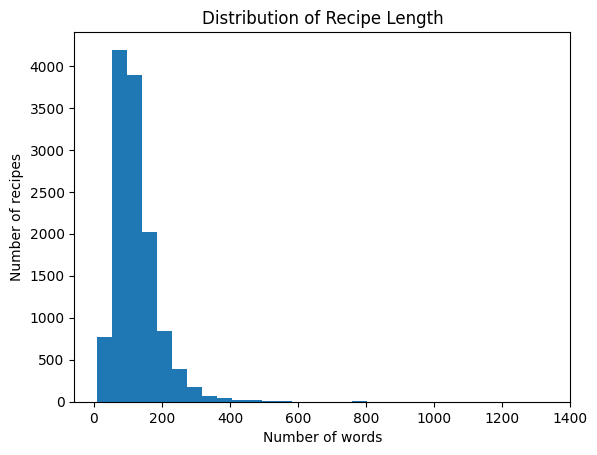

In [ ]:
plt.hist(df_train["recette_len"], bins=30)
plt.title("Distribution of Recipe Length")
plt.xlabel("Number of words")
plt.ylabel("Number of recipes")
plt.show()

**Recipe Instructions Length**

| Statistic | Value
|-----|------|
| Mean | 123.6 words |
| Median | 109 words |
| Minimum | 9 word |
| Maximum | 1334 word |

Recipe instructions are **much longer** and **more variable** than titles. Most recipes contain between **80** and **150** words, although some recipes are much longer, leading to extreme values (up to **1334** words).

**Interpretation**

These results suggest that:

* Titles are short but often contain strong semantic signals about the recipe category.

* Recipe instructions contain much richer lexical information, which can help models capture more contextual clues.

* Therefore, using both titles and instructions together is likely beneficial for building robust classification models.

* The large variability in recipe length should be considered when applying text vectorization methods.

## 4. Lexical Analysis

In [ ]:
FR_STOPWORDS = [
    'le','la','les','de','du','des','un','une','et','en','au','aux',
    'à','par','sur','pour','dans','avec','se','si','il','elle','ils',
    'elles','on','nous','vous','que','qui','ce','est','pas','plus',
    'bien','tout','très','cette','ces','son','sa','ses','ou','ne',
    'l','d','y','je','tu','leur','leurs','y','me','te','lui'
]

In [ ]:
df_train["text"] = df_train["titre"] + " " + df_train["recette"]

In [ ]:
from sklearn.feature_extraction.text import CountVectorizer

vectorizer = CountVectorizer(stop_words=FR_STOPWORDS, max_features=10)

X = vectorizer.fit_transform(df_train["text"])

words = vectorizer.get_feature_names_out()
counts = X.toarray().sum(axis=0)

import pandas as pd
freq_df = pd.DataFrame({"word": words, "count": counts}).sort_values(by="count", ascending=False)

freq_df

,word,count
3,faire,14422
0,ajouter,12545
9,puis,9688
1,cuire,8962
4,four,8872
6,mettre,7965
8,pendant,7440
5,laisser,7089
7,min,7036
2,eau,6984


In [ ]:
desserts = df_train[df_train["type"] == "Dessert"]["text"]

vectorizer = CountVectorizer(stop_words=FR_STOPWORDS, max_features=10)

X = vectorizer.fit_transform(desserts)

words = vectorizer.get_feature_names_out()
counts = X.toarray().sum(axis=0)

pd.DataFrame({"word": words, "count": counts}).sort_values(by="count", ascending=False)

,word,count
9,sucre,5025
8,pâte,3727
3,faire,3472
0,ajouter,3462
4,four,3313
7,puis,3093
1,chocolat,2924
2,crème,2869
6,mélanger,2818
5,mettre,2612


In [ ]:
entree = df_train[df_train["type"] == "Entrée"]["text"]

vectorizer = CountVectorizer(stop_words=FR_STOPWORDS, max_features=10)

X = vectorizer.fit_transform(entree)

words = vectorizer.get_feature_names_out()
counts = X.toarray().sum(axis=0)

pd.DataFrame({"word": words, "count": counts}).sort_values(by="count", ascending=False)

,word,count
4,faire,2851
0,ajouter,2430
9,puis,2060
2,cuire,1811
7,mettre,1724
5,four,1696
3,eau,1601
6,huile,1544
8,pendant,1485
1,couper,1412


In [ ]:
plat_principal = df_train[df_train["type"] == "Plat principal"]["text"]

vectorizer = CountVectorizer(stop_words=FR_STOPWORDS, max_features=10)

X = vectorizer.fit_transform(plat_principal)

words = vectorizer.get_feature_names_out()
counts = X.toarray().sum(axis=0)

pd.DataFrame({"word": words, "count": counts}).sort_values(by="count", ascending=False)

,word,count
3,faire,8099
0,ajouter,6653
1,cuire,5182
9,puis,4535
8,pendant,3901
2,eau,3892
4,four,3863
5,huile,3818
7,min,3805
6,laisser,3796


### Vocabulary Analysis

To better understand the lexical characteristics of the dataset, we extracted the most frequent words from the corpus using a bag-of-words approach with stopword removal.

The global vocabulary is dominated by **generic cooking verbs and instructions**, such as *faire*, *ajouter*, *cuire*, and *mettre*. These words appear frequently across all recipe types and therefore are not strongly discriminative.

However, when analyzing the vocabulary per class, some patterns emerge:

* **Dessert recipes** contain distinctive lexical cues related to sweet ingredients, such as *sucre*, *chocolat*, *crème*, and *pâte*.
* **Entrée recipes** contain more general preparation terms such as *couper*, *huile*, and *eau*.
* **Plat principal recipes** are characterized by cooking-related terms such as *cuire*, *pendant*, and *huile*.

These observations suggest that dessert recipes may be easier to identify due to the presence of specific ingredients, while **Entrée and Plat principal share more similar vocabulary**, which may make them harder to distinguish automatically.


In [ ]:
from sklearn.feature_extraction.text import CountVectorizer

vectorizer = CountVectorizer(stop_words=FR_STOPWORDS, max_features=10)

X = vectorizer.fit_transform(df_train["ingredients"])

words = vectorizer.get_feature_names_out()
counts = X.toarray().sum(axis=0)

freq_ing = pd.DataFrame({
    "ingredient": words,
    "count": counts
}).sort_values(by="count", ascending=False)

freq_ing

,ingredient,count
8,soupe,8325
7,sel,7144
6,poivre,6112
1,cl,5943
4,cuillères,5802
3,cuillère,5460
9,sucre,5064
0,beurre,4422
5,huile,4329
2,crème,3985


In [ ]:
desserts = df_train[df_train["type"] == "Dessert"]["ingredients"]

from sklearn.feature_extraction.text import CountVectorizer

vectorizer = CountVectorizer(stop_words=FR_STOPWORDS, max_features=10)

X = vectorizer.fit_transform(desserts)

words = vectorizer.get_feature_names_out()
counts = X.toarray().sum(axis=0)

freq_ing = pd.DataFrame({
    "ingredient": words,
    "count": counts
}).sort_values(by="count", ascending=False)

freq_ing

,ingredient,count
9,sucre,4569
8,soupe,2179
1,beurre,2163
5,farine,1995
6,oeufs,1853
2,cl,1818
0,100,1645
7,poudre,1626
4,cuillères,1625
3,cuillère,1523


In [ ]:
plat_principal_ing = df_train[df_train["type"] == "Plat principal"]["ingredients"]

from sklearn.feature_extraction.text import CountVectorizer

vectorizer = CountVectorizer(stop_words=FR_STOPWORDS, max_features=10)

X = vectorizer.fit_transform(plat_principal_ing)

words = vectorizer.get_feature_names_out()
counts = X.toarray().sum(axis=0)

freq_ing = pd.DataFrame({
    "ingredient": words,
    "count": counts
}).sort_values(by="count", ascending=False)

freq_ing

,ingredient,count
8,sel,4238
9,soupe,4177
7,poivre,4097
1,cl,2927
4,cuillères,2861
5,huile,2751
3,cuillère,2683
0,ail,1897
2,crème,1793
6,olive,1740


In [ ]:
entree_ing = df_train[df_train["type"] == "Entrée"]["ingredients"]

from sklearn.feature_extraction.text import CountVectorizer

vectorizer = CountVectorizer(stop_words=FR_STOPWORDS, max_features=10)

X = vectorizer.fit_transform(entree_ing)

words = vectorizer.get_feature_names_out()
counts = X.toarray().sum(axis=0)

freq_ing = pd.DataFrame({
    "ingredient": words,
    "count": counts
}).sort_values(by="count", ascending=False)

freq_ing

,ingredient,count
8,sel,2084
7,poivre,1987
9,soupe,1969
3,cuillères,1316
5,huile,1276
2,cuillère,1254
0,cl,1198
1,crème,955
6,olive,803
4,fraîche,700


### Ingredient Analysis

We also analyzed the vocabulary extracted from the **ingredients** column in order to identify ingredients that may characterize each recipe category.

The most frequent tokens in the ingredient lists include common cooking components such as *sel*, *poivre*, *huile*, and *crème*. Some tokens correspond to measurement expressions (e.g., *cl*, *cuillère*, *cuillères*, *soupe*), which appear frequently because ingredient lists often include quantities and units.

When examining ingredients per class, clearer patterns emerge:

* **Dessert recipes** frequently contain ingredients associated with sweet preparations, such as *sucre*, *beurre*, *farine*, and *oeufs*.
* **Plat principal recipes** often include savory cooking ingredients such as *ail*, *huile*, *olive*, and *crème*.
* **Entrée recipes** share many ingredients with Plat principal (e.g., *huile*, *sel*, *poivre*, *crème*), suggesting that these two categories may be harder to distinguish.

These observations indicate that ingredient information provides useful semantic cues for classification. However, the overlap between **Entrée** and **Plat principal** ingredients may lead to classification ambiguities.


## Missing Values

In [ ]:
df_train.isnull().sum()

,0
doc_id,0
titre,0
type,0
difficulte,0
cout,0
ingredients,0
recette,0
titre_len,0
recette_len,0
text,0


In [ ]:
(df_train[['titre','recette','ingredients']] == '').sum()

,0
titre,0
recette,0
ingredients,0


### Missing Values Analysis

Before training classification models, we verified the presence of missing values in the dataset.

We inspected the main columns used for the task (`titre`, `recette`, `ingredients`, and `type`) and found **no missing values** in the training data.

This indicates that the dataset is well-formed and does not require additional preprocessing steps to handle incomplete records.


In [ ]:
df_train[['doc_id','titre','ingredients','recette','type']].head(3)

,doc_id,titre,ingredients,recette,type
0,recette_221358.xml,"Feuilleté de saumon et de poireau, sauce aux c...",- 1 gros pavé de saumon - 100 g de crevettes d...,Couper finement le blanc et un peu de vert des...,Plat principal
1,recette_48656.xml,Cake poulet/moutarde/amandes,- 3 œufs - 150 g de farine - 1 sachet de levur...,"Couper finement l'échalote, la faire revenir à...",Entrée
2,recette_30049.xml,Bûche à la truite fumée (7ème rencontre),- 800 g de filet de truite saumonnée fumée en ...,Faites blanchir les épinards à l'eau bouillant...,Entrée


In [ ]:
df_train[['doc_id','titre','ingredients','recette','type']].sample(3, random_state=42)

,doc_id,titre,ingredients,recette,type
10533,recette_169081.xml,Tarte poireaux saumon Philadelphia,- 3 beaux poireaux - 100 à 150 g de saumon fum...,Faire cuire à blanc la pâte brisée : 5 à 7 min...,Plat principal
927,recette_56542.xml,Gratin de pommes de terre complet,- 10 pommes de terre - 10 tranches lard détail...,Cuire les pommes de terre à l'eau bouillante. ...,Plat principal
1965,recette_90821.xml,Charlotte aux fraises facile,- 450 g de fraises - 30 biscuits cuillers - 50...,Mettre au congélateur pendant 30 minutes mini ...,Dessert


## Example Recipes

To better understand the structure of the dataset, we inspected several recipes from the training set. Each document contains an identifier (`doc_id`), a title (`titre`), a list of ingredients (`ingredients`), recipe instructions (`recette`), and a category label (`type`).

### Example 1

* **ID:** recette_169081.xml
* **Title:** Tarte poireaux saumon Philadelphia
* **Type:** Plat principal

**Ingredients (Some of):**
poireaux, saumon fumé, fromage Philadelphia, crème liquide, pâte brisée, emmental râpé.

**Description:**
This recipe describes the preparation of a savory tart with leeks and smoked salmon. The instructions include several preparation steps such as cooking the leeks, preparing the dough, and baking the tart in the oven.

---

### Example 2

* **ID:** recette_56542.xml
* **Title:** Gratin de pommes de terre complet
* **Type:** Plat principal

**Ingredients (Some of):**
pommes de terre, lardons, champignons, fromage de chèvre, crème fraîche, basilic.

**Description:**
This recipe explains how to prepare a potato gratin with mushrooms and goat cheese. The preparation involves cooking the potatoes, sautéing ingredients, assembling layers, and baking the dish in the oven.

---

### Example 3

* **ID:** recette_90821.xml
* **Title:** Charlotte aux fraises facile
* **Type:** Dessert

**Ingredients (Some of):**
fraises, biscuits cuillers, crème fraîche, sucre, sirop de canne.

**Description:**
This dessert recipe explains how to prepare a strawberry charlotte by layering biscuits soaked in syrup with whipped cream and fresh strawberries, then refrigerating the dessert for several hours.


### Run1: Random Baseline


In [ ]:
labels = df_train["type"].unique()

In [ ]:
import numpy as np

np.random.seed(42)

random_predictions = np.random.choice(labels, size=len(df_test))

In [ ]:
y_true = df_test["type"]

accuracy = accuracy_score(y_true, random_predictions)

macro_f1 = f1_score(y_true, random_predictions, average="macro")

micro_f1 = f1_score(y_true, random_predictions, average="micro")

print("Accuracy:", accuracy)
print("Macro F1:", macro_f1)
print("Micro F1:", micro_f1)

Accuracy: 0.3451008645533141
Macro F1: 0.3367993024908092
Micro F1: 0.3451008645533141


In [ ]:
cm = confusion_matrix(y_true, random_predictions)

print(cm)

[[145 135 127]
 [107 106 124]
 [205 211 228]]



As a first baseline, we implemented a random classifier that assigns a random label among the three possible classes (Entrée, Plat principal, Dessert) to each recipe in the test set.

This baseline represents the performance of a system with no knowledge of the data and serves as a lower bound for the task.

| Metric   | Score |
| -------- | ----- |
| Accuracy | 0.345 |
| Macro-F1 | 0.337 |
| Micro-F1 | 0.345 |

The results are close to the theoretical expectation for a three-class random classifier (approximately 33%). This confirms that the baseline behaves as expected and provides a reference point for evaluating more advanced models.


### Run2: Majority Class Baseline


In [ ]:
df_train["type"].value_counts()

majority_class = df_train["type"].value_counts().idxmax()

majority_predictions = [majority_class] * len(df_test)

y_true = df_test["type"]

accuracy = accuracy_score(y_true, majority_predictions)
macro_f1 = f1_score(y_true, majority_predictions, average="macro")
micro_f1 = f1_score(y_true, majority_predictions, average="micro")

print("Majority class:", majority_class)
print("Accuracy:", accuracy)
print("Macro F1:", macro_f1)
print("Micro F1:", micro_f1)

Majority class: Plat principal
Accuracy: 0.46397694524495675
Macro F1: 0.21128608923884515
Micro F1: 0.46397694524495675



As a second baseline, we implemented a majority class classifier that always predicts the most frequent class observed in the training data.

In this dataset, the most frequent label is **Plat principal**, so this baseline assigns this label to every recipe in the test set.

| Metric   | Score |
| -------- | ----- |
| Accuracy | 0.464 |
| Macro-F1 | 0.211 |
| Micro-F1 | 0.464 |

Although the accuracy appears relatively high (around 46%), this baseline completely ignores the other classes. As a result, the **Macro-F1 score is very low**, since the classifier fails to correctly predict **Entrée** and **Dessert** recipes.

This result highlights the importance of using evaluation metrics such as **Macro-F1**, which account for class imbalance and ensure that performance is measured fairly across all classes.


## Run3: TF-IDF + Naive Bayes


Accuracy: 0.8105187319884726
Macro F1: 0.7538405652778232
Micro F1: 0.8105187319884726

Classification Report:

                precision    recall  f1-score   support

       Dessert       0.95      0.99      0.97       407
        Entrée       0.84      0.32      0.46       337
Plat principal       0.73      0.96      0.83       644

      accuracy                           0.81      1388
     macro avg       0.84      0.75      0.75      1388
  weighted avg       0.82      0.81      0.78      1388



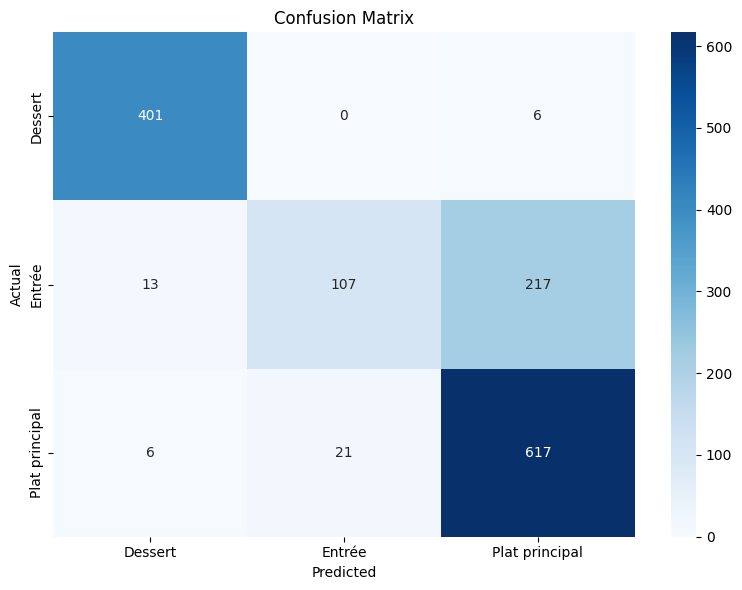

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
import seaborn as sns


df_train["text"] = df_train["titre"] + " " + df_train["recette"]
df_test["text"] = df_test["titre"] + " " + df_test["recette"]

X_train = df_train["text"]
y_train = df_train["type"]

X_test = df_test["text"]
y_test = df_test["type"]

vectorizer = TfidfVectorizer(
    stop_words=FR_STOPWORDS,
    ngram_range=(1, 1),
    max_features=10000
)

X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

clf = MultinomialNB()
clf.fit(X_train_tfidf, y_train)

y_pred = clf.predict(X_test_tfidf)

accuracy = accuracy_score(y_test, y_pred)
macro_f1 = f1_score(y_test, y_pred, average="macro")
micro_f1 = f1_score(y_test, y_pred, average="micro")

print("Accuracy:", accuracy)
print("Macro F1:", macro_f1)
print("Micro F1:", micro_f1)

print("\nClassification Report:\n")
print(classification_report(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred)
labels = sorted(set(y_test) | set(y_pred))

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.tight_layout()
plt.show()

In [ ]:

feature_names = np.array(vectorizer.get_feature_names_out())

for i, class_label in enumerate(clf.classes_):
    top10_idx = np.argsort(clf.feature_log_prob_[i])[-10:][::-1]
    top10_words = feature_names[top10_idx]
    print(f"{class_label}: {', '.join(top10_words)}")

Dessert: sucre, chocolat, pâte, four, mélanger, ajouter, moule, gâteau, crème, beurre
Entrée: faire, ajouter, salade, puis, mettre, couper, four, huile, tomates, cuire
Plat principal: faire, ajouter, poulet, cuire, sauce, puis, huile, min, plat, feu


### Approach: (Title + Instructions)

For our first real classification model, we used a **TF-IDF representation** of the text combined with a **Naive Bayes** classifier.

The input text was created by concatenating the **recipe title** and the **recipe instructions**.

| Metric   | Score |
| -------- | ----- |
| Accuracy | 0.811 |
| Macro-F1 | 0.754 |
| Micro-F1 | 0.811 |

The model performs significantly better than the baselines, demonstrating that lexical information from the recipes is highly informative for classification.

A detailed analysis shows that:

* **Dessert recipes are detected very accurately**, with an F1 score of 0.97. This is likely due to the presence of distinctive vocabulary such as *sucre*, *chocolat*, *gâteau*, *crème*, and *beurre*.
* **Plat principal recipes are also well recognized**, with an F1 score of 0.83, driven by words such as *poulet*, *sauce*, *plat*, and *feu*.
* **Entrée recipes are more difficult to classify**, with a much lower recall. Many Entrée recipes are incorrectly predicted as Plat principal.

By inspecting the most informative words learned by the model, we observe:

* **Dessert** is characterized by strong, specific lexical cues: *sucre*, *chocolat*, *pâte*, *gâteau*, *crème*, *beurre*.
* **Entrée** contains more generic preparation and ingredient terms: *salade*, *tomates*, *huile*, *couper*, *faire*.
* **Plat principal** is associated with cooking actions and main ingredients: *poulet*, *cuire*, *sauce*, *plat*, *feu*.

These results confirm that **Dessert vocabulary is highly distinctive**, while **Entrée and Plat principal share many common cooking terms**, which explains the confusion between these two classes.


Accuracy: 0.8119596541786743
Macro F1: 0.7532181379864088
Micro F1: 0.8119596541786743

Classification Report:

                precision    recall  f1-score   support

       Dessert       0.96      1.00      0.98       407
        Entrée       0.83      0.31      0.45       337
Plat principal       0.74      0.96      0.83       644

      accuracy                           0.81      1388
     macro avg       0.84      0.75      0.75      1388
  weighted avg       0.82      0.81      0.78      1388



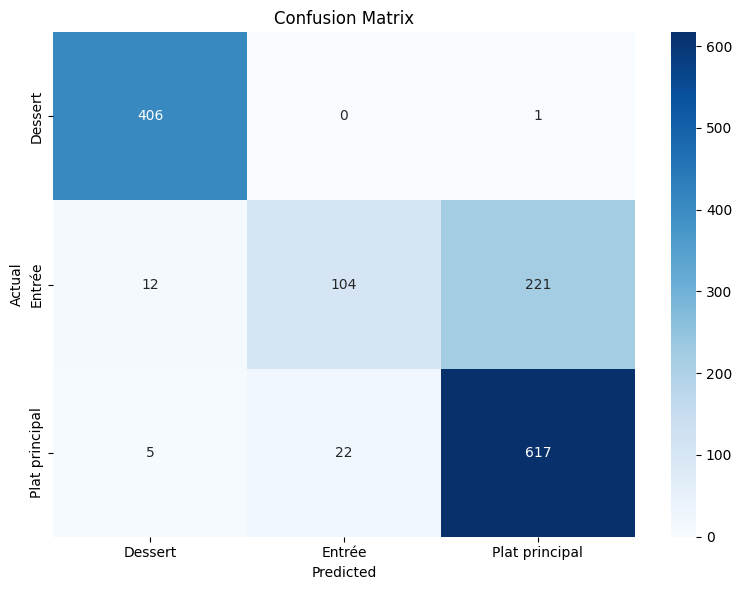

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB

df_train["text"] = df_train["titre"] + " " + df_train["recette"] + " " + df_train["ingredients"]
df_test["text"] = df_test["titre"] + " " + df_test["recette"] + " " + df_test["ingredients"]

X_train = df_train["text"]
y_train = df_train["type"]

X_test = df_test["text"]
y_test = df_test["type"]

vectorizer = TfidfVectorizer(
    stop_words=FR_STOPWORDS,
    ngram_range=(1, 1),
    max_features=10000
)

X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

clf = MultinomialNB()
clf.fit(X_train_tfidf, y_train)

y_pred = clf.predict(X_test_tfidf)

accuracy = accuracy_score(y_test, y_pred)
macro_f1 = f1_score(y_test, y_pred, average="macro")
micro_f1 = f1_score(y_test, y_pred, average="micro")

print("Accuracy:", accuracy)
print("Macro F1:", macro_f1)
print("Micro F1:", micro_f1)

print("\nClassification Report:\n")
print(classification_report(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred)
labels = sorted(set(y_test) | set(y_pred))

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.tight_layout()
plt.show()

Accuracy: 0.7845821325648416
Macro F1: 0.6959034780808393
Micro F1: 0.7845821325648416

Classification Report:

                precision    recall  f1-score   support

       Dessert       0.96      0.99      0.98       407
        Entrée       0.77      0.18      0.30       337
Plat principal       0.70      0.97      0.81       644

      accuracy                           0.78      1388
     macro avg       0.81      0.71      0.70      1388
  weighted avg       0.79      0.78      0.74      1388



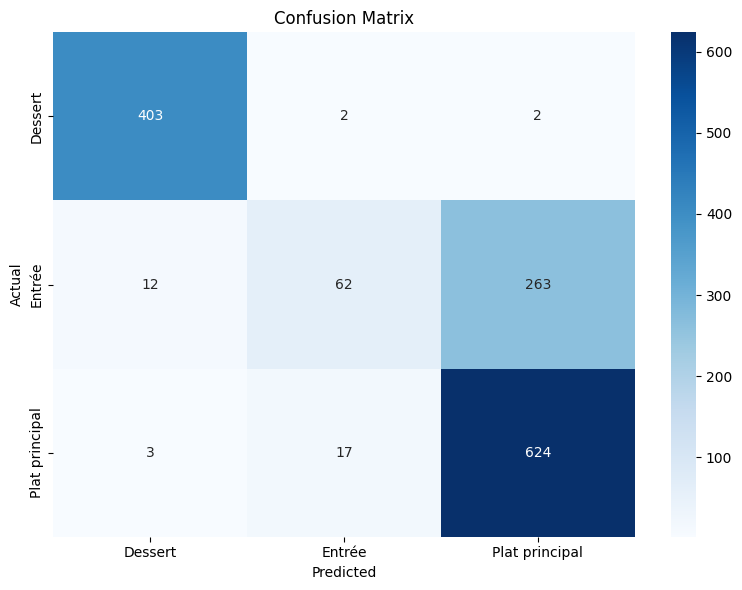

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB

df_train["text"] =  df_train["ingredients"]
df_test["text"] =  df_test["ingredients"]

X_train = df_train["text"]
y_train = df_train["type"]

X_test = df_test["text"]
y_test = df_test["type"]

vectorizer = TfidfVectorizer(
    stop_words=FR_STOPWORDS,
    ngram_range=(1, 1),
    max_features=10000
)

X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

clf = MultinomialNB()
clf.fit(X_train_tfidf, y_train)

y_pred = clf.predict(X_test_tfidf)

accuracy = accuracy_score(y_test, y_pred)
macro_f1 = f1_score(y_test, y_pred, average="macro")
micro_f1 = f1_score(y_test, y_pred, average="micro")

print("Accuracy:", accuracy)
print("Macro F1:", macro_f1)
print("Micro F1:", micro_f1)

print("\nClassification Report:\n")
print(classification_report(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred)
labels = sorted(set(y_test) | set(y_pred))

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.tight_layout()
plt.show()

### Additional Experiments: Input Variations

We also evaluated two alternative input representations using the same TF-IDF + Naive Bayes model.

#### Title + Instructions + Ingredients

| Metric   | Score |
| -------- | ----- |
| Accuracy | 0.812 |
| Macro-F1 | 0.753 |
| Micro-F1 | 0.812 |

Adding the **ingredients** to the input text does not significantly improve performance compared to using only the title and instructions.

This can be explained by the fact that:

* Many ingredient names already appear in the recipe instructions.
* Ingredient lists introduce some noise (e.g., measurement terms such as *cl*, *cuillère*, *soupe*).

As a result, the additional information provided by ingredients is largely redundant.

---

#### Ingredients Only

| Metric   | Score |
| -------- | ----- |
| Accuracy | 0.785 |
| Macro-F1 | 0.696 |
| Micro-F1 | 0.785 |

Using only the **ingredients** leads to a noticeable drop in performance.

While ingredient lists contain useful signals (e.g., *sucre*, *beurre* for desserts), they lack:

* contextual information
* preparation steps
* cooking actions

This results in poorer discrimination, especially between **Entrée** and **Plat principal**, which often share similar ingredients.

---

#### Conclusion

These experiments show that:

* The **recipe instructions are the most informative source of information**.
* The **title provides useful complementary signals**.
* The **ingredients alone are insufficient**, and adding them to the text brings only marginal improvement.

This justifies using **title + instructions** as the main input for subsequent models.


### Run4: TF-IDF + Logistic Regression (with n-grams)


Accuracy: 0.8782420749279539
Macro F1: 0.867155967868646
Micro F1: 0.8782420749279539

Classification Report:

                precision    recall  f1-score   support

       Dessert       0.98      0.99      0.99       407
        Entrée       0.80      0.68      0.74       337
Plat principal       0.85      0.91      0.88       644

      accuracy                           0.88      1388
     macro avg       0.88      0.86      0.87      1388
  weighted avg       0.88      0.88      0.88      1388



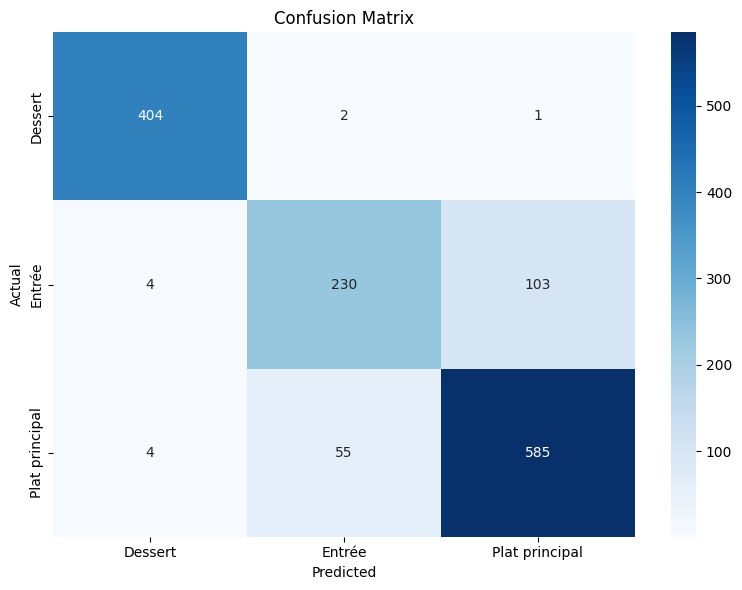

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

df_train["text"] = df_train["titre"] + " " + df_train["recette"]
df_test["text"] = df_test["titre"] + " " + df_test["recette"]

X_train = df_train["text"]
y_train = df_train["type"]

X_test = df_test["text"]
y_test = df_test["type"]

vectorizer = TfidfVectorizer(
    stop_words=FR_STOPWORDS,
    ngram_range=(1, 2),
    max_features=20000
)

X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

clf = LogisticRegression(max_iter=1000)
clf.fit(X_train_tfidf, y_train)

y_pred = clf.predict(X_test_tfidf)

accuracy = accuracy_score(y_test, y_pred)
macro_f1 = f1_score(y_test, y_pred, average="macro")
micro_f1 = f1_score(y_test, y_pred, average="micro")

print("Accuracy:", accuracy)
print("Macro F1:", macro_f1)
print("Micro F1:", micro_f1)

print("\nClassification Report:\n")
print(classification_report(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred)
labels = sorted(set(y_test) | set(y_pred))

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
import pandas as pd

feature_names = np.array(vectorizer.get_feature_names_out())

for i, class_label in enumerate(clf.classes_):
    top10_idx = np.argsort(clf.coef_[i])[-10:][::-1]

    top_features = feature_names[top10_idx]
    top_scores = clf.coef_[i][top10_idx]

    df_top = pd.DataFrame({
        "feature": top_features,
        "weight": top_scores
    })

    print(f"\nTop 10 features for class: {class_label}")
    print(df_top)


Top 10 features for class: Dessert
    feature    weight
0     sucre  9.376432
1  chocolat  5.010756
2    gâteau  3.025418
3    fruits  2.997495
4   vanille  2.766487
5     glace  2.581882
6   fraises  2.391686
7   dessert  2.317861
8      lait  2.173144
9    pommes  2.171784

Top 10 features for class: Entrée
      feature    weight
0       soupe  3.516676
1      salade  3.339415
2     terrine  2.853200
3      entrée  2.749260
4     velouté  2.602072
5       mixer  2.204457
6  ciboulette  2.185806
7      potage  2.175996
8  mayonnaise  2.115836
9    vinaigre  2.076288

Top 10 features for class: Plat principal
     feature    weight
0     poulet  3.956447
1     viande  3.951716
2      sauce  3.174444
3       plat  3.173275
4      pâtes  3.101985
5        riz  2.773633
6     gratin  2.733377
7       rôti  2.321198
8  escalopes  2.153689
9      poêle  2.128530


In [ ]:
coef_abs = np.abs(clf.coef_).sum(axis=0)

top_idx = np.argsort(coef_abs)[-20:][::-1]

top_features = feature_names[top_idx]

print("Top global features:")
print(top_features)

Top global features:
['sucre' 'chocolat' 'poulet' 'viande' 'soupe' 'salade' 'sauce' 'plat'
 'pâtes' 'poivre' 'gâteau' 'fruits' 'terrine' 'tomates' 'riz' 'vanille'
 'entrée' 'gratin' 'sel poivre' 'velouté']


In [ ]:
df_test["pred"] = y_pred

errors = df_test[df_test["type"] != df_test["pred"]]

errors.sample(10, random_state=42)[["titre","type","pred"]]

,titre,type,pred
1154,Tourte sans pâte aux champignons,Entrée,Plat principal
233,"Duo de saint jacques et loup, crème gingembre ...",Entrée,Plat principal
1027,Tarte aux scampis,Plat principal,Entrée
231,Salade de soja et crevettes aux agrumes,Plat principal,Entrée
1205,Gratin léger d'endives au thon,Entrée,Plat principal
1317,Quiche ail et fines herbes,Plat principal,Entrée
1362,"Tarte aux quatres fromages (emmental, Brousse,...",Plat principal,Entrée
422,Galette aux deux sons,Dessert,Plat principal
950,Niçoise aux anchois,Entrée,Plat principal
488,Noix de jambon façon Jambon de pays,Entrée,Plat principal



To improve upon the limitations observed with the Naive Bayes model, we implemented a **Logistic Regression classifier** combined with a **TF-IDF representation using both unigrams and bigrams (n-grams 1–2)**.

The input text remains the concatenation of the **recipe title** and the **recipe instructions**.

#### Method description

* **Features used:** TF-IDF representation of `titre + recette`
* **Vectorization:** n-grams (1,2)
* **Classifier:** Logistic Regression

This approach addresses two main limitations of the previous model:

* Unlike Naive Bayes, Logistic Regression **does not assume independence between words**, allowing it to better capture relationships between features.
* The use of **bigrams** enables the model to capture meaningful expressions such as *“salade tomate”*, *“poulet rôti”*, or *“gâteau chocolat”*, which are more informative than individual words.

---

#### Results

| Metric   | Score |
| -------- | ----- |
| Accuracy | 0.878 |
| Macro-F1 | 0.867 |
| Micro-F1 | 0.878 |

The model shows a **significant improvement** over Run 3 (Naive Bayes), particularly in terms of **Macro-F1**, indicating better performance across all classes.

---

#### Detailed analysis

* **Dessert recipes are almost perfectly classified**, with an F1 score of 0.99.
* **Plat principal recipes are very well recognized**, with an F1 score of 0.88.
* **Entrée classification improves substantially**, with recall increasing from 0.32 (Run 3) to 0.68.

The confusion between **Entrée** and **Plat principal** is still present but has been significantly reduced.

---

#### Feature analysis (model interpretability)

To better understand how the model makes its predictions, we analyzed the **most important features (words and n-grams) learned by Logistic Regression**.

##### Top features per class

* **Dessert:** *sucre*, *chocolat*, *gâteau*, *fruits*, *vanille*, *glace*, *fraises*, *lait*, *pommes*
  → These features clearly correspond to **sweet ingredients and desserts**, making this class highly distinctive.

* **Entrée:** *soupe*, *salade*, *terrine*, *velouté*, *potage*, *mayonnaise*, *vinaigre*, *ciboulette*
  → These features are associated with **light dishes, soups, and cold preparations**, which characterize appetizers.

* **Plat principal:** *poulet*, *viande*, *sauce*, *plat*, *pâtes*, *riz*, *gratin*, *rôti*, *poêle*
  → These features correspond to **main ingredients and cooking methods**, typical of main courses.

##### Global important features

Across all classes, the most influential features include:

*sucre*, *chocolat*, *poulet*, *viande*, *soupe*, *salade*, *sauce*, *plat*, *pâtes*, *gâteau*, *riz*, *gratin*

---

#### Interpretation

This analysis highlights several key insights:

* The model relies heavily on **ingredient names**, which are highly informative for classification.
* **Dessert recipes are easy to identify** due to strong and unique lexical signals (e.g., *sucre*, *chocolat*).
* **Entrée recipes are characterized by specific dish types** (e.g., *soupe*, *salade*, *terrine*), which helps improve their detection compared to Run 3.
* **Plat principal recipes are associated with proteins and basic food elements** (e.g., *poulet*, *viande*, *riz*).

The use of **n-grams and a discriminative model** allows better separation between classes, especially between **Entrée and Plat principal**, although some overlap still remains.

Overall, the model’s behavior is consistent with both the exploratory data analysis and the previous results, confirming that it has successfully learned meaningful patterns from the data.


In [ ]:
probs = clf.predict_proba(X_test_tfidf)

max_probs = probs.max(axis=1)

df_test["confidence"] = max_probs

df_test.sort_values("confidence").head(10)

,doc_id,titre,type,difficulte,cout,ingredients,recette,text,pred,confidence
335,recette_172281.xml,Tarte normande à l'andouille de Vire,Entrée,Facile,Moyen,- 1 pâte brisée - 25 cl de crème (crue de préf...,Mettre la pâte brisée dans un plat à tarte et ...,Tarte normande à l'andouille de Vire Mettre la...,Entrée,0.346182
674,recette_174102.xml,Oeuf poché ultra simple,Entrée,Facile,Bon marché,- 1 œuf - de l'eau - 1 minuteur,Faites bouillir de l'eau dans une casserole (i...,Oeuf poché ultra simple Faites bouillir de l'e...,Entrée,0.349745
1259,recette_25047.xml,Pain maison à la levure de bière,Entrée,Facile,Moyen,- 750 g de farine de blé - 30 g de levure de b...,"Délayer la levure dans l'eau, ajouter la farin...",Pain maison à la levure de bière Délayer la le...,Dessert,0.352429
1143,recette_57099.xml,Pain safrané à la machine à pain,Entrée,Très facile,Moyen,- 1 sachet de levure sèche de boulanger (soit ...,Faire chauffer au micro-ondes dans une tasse l...,Pain safrané à la machine à pain Faire chauffe...,Dessert,0.376926
1288,recette_71999.xml,Flan de macédoine au yaourt de brebis,Entrée,Très facile,Bon marché,- 1 yaourt de brebis - 1 oeuf - 1 cuillère à s...,"Mélanger l'oeuf avec le yaourt, assaisonner, p...",Flan de macédoine au yaourt de brebis Mélanger...,Entrée,0.385610
461,recette_84162.xml,Cake au roquefort et aux noix,Entrée,Très facile,Bon marché,- 3 oeufs - 150 g farine - 1 sachet de levure ...,"Battre les oeufs avec le lait et les huiles, i...",Cake au roquefort et aux noix Battre les oeufs...,Entrée,0.386263
442,recette_166605.xml,Bûche au saumon fumé,Entrée,Très facile,Bon marché,- 8 oeufs - 300 g de saumon fumé - 400 g de ro...,"Séparez les jaunes et les blancs d'oeufs, batt...",Bûche au saumon fumé Séparez les jaunes et les...,Entrée,0.404656
137,recette_69780.xml,Tarte au thon et aux herbes,Entrée,Très facile,Bon marché,- 1 pâte brisée - 1 grosse boîte de thon (ou t...,"Préchauffez le four à 230°C(thermostat 7/8), p...",Tarte au thon et aux herbes Préchauffez le fou...,Entrée,0.410425
80,recette_20873.xml,Croustade marinière,Plat principal,Très facile,Moyen,- une pâte feuilletée - 1 boîte de concentré d...,Poser la pâte feuilletée sur une plaque allant...,Croustade marinière Poser la pâte feuilletée s...,Plat principal,0.413554
1127,recette_43756.xml,Pain pour machine à pain,Plat principal,Très facile,Bon marché,- 3 tasses de farine multi-céréales - 2 cuillè...,Les proportions sont données à partir des tass...,Pain pour machine à pain Les proportions sont ...,Entrée,0.414316


In [ ]:
threshold = 0.60

low_conf = df_test[df_test["confidence"] < threshold]

print("Number of low-confidence predictions:", len(low_conf))
print("\nDifficulty counts among low-confidence predictions:")
print(low_conf["difficulte"].value_counts(dropna=False))

Number of low-confidence predictions: 202

Difficulty counts among low-confidence predictions:
difficulte
Très facile              113
Facile                    82
Moyennement difficile      7
Name: count, dtype: int64


In [ ]:
print("\nOverall difficulty distribution:")
print(df_test["difficulte"].value_counts(dropna=False))


Overall difficulty distribution:
difficulte
Très facile              697
Facile                   576
Moyennement difficile    107
Difficile                  8
Name: count, dtype: int64


In [ ]:
low_conf_props = low_conf["difficulte"].value_counts(normalize=True, dropna=False).sort_index()
overall_props = df_test["difficulte"].value_counts(normalize=True, dropna=False).sort_index()

comparison = pd.DataFrame({
    "low_conf_count": low_conf["difficulte"].value_counts(dropna=False).sort_index(),
    "low_conf_prop": low_conf_props,
    "overall_count": df_test["difficulte"].value_counts(dropna=False).sort_index(),
    "overall_prop": overall_props
}).fillna(0)



### Additional Analysis: Prediction Confidence and Recipe Difficulty

We analyzed the relationship between model confidence and the **difficulty level** of recipes to determine whether certain types of recipes are inherently harder to classify.

We focused on predictions with **low confidence** (probability < 0.60) and compared their distribution of difficulty levels with the overall dataset.

| Difficulty            | Low-confidence proportion | Overall proportion | Difference |
| --------------------- | ------------------------- | ------------------ | ---------- |
| Très facile           | 0.56                      | 0.50               | +0.06      |
| Facile                | 0.41                      | 0.41               | -0.01      |
| Moyennement difficile | 0.03                      | 0.08               | -0.04      |
| Difficile             | 0.00                      | 0.01               | -0.01      |

#### Interpretation

At first glance, most low-confidence predictions correspond to **“Très facile”** and **“Facile”** recipes. However, this is expected since these categories are also the most frequent in the dataset.

When comparing proportions:

* **“Très facile” recipes are only slightly over-represented** among low-confidence predictions (+0.06).
* **“Facile” recipes appear in similar proportion** to the overall dataset.
* More difficult recipes are actually **under-represented** among uncertain predictions.

This suggests that:

* The relationship between **recipe difficulty and classification uncertainty is weak**.
* The model’s uncertainty is primarily driven by **textual ambiguity (e.g., overlapping vocabulary between Entrée and Plat principal)** rather than recipe difficulty.

#### Conclusion

Recipe difficulty does not appear to be a strong factor influencing model confidence. Therefore, incorporating this feature is unlikely to significantly improve classification performance.


### Run5: Enriched Model (TF-IDF + Additional Features)


In [ ]:

df_train["titre_len"] = df_train["titre"].str.split().str.len()
df_test["titre_len"] = df_test["titre"].str.split().str.len()

df_train["recette_len"] = df_train["recette"].str.split().str.len()
df_test["recette_len"] = df_test["recette"].str.split().str.len()

df_train["num_ingredients"] = df_train["ingredients"].str.count("-")
df_test["num_ingredients"] = df_test["ingredients"].str.count("-")

In [ ]:
sweet_words = ["sucre", "chocolat", "crème", "vanille"]
savory_words = ["huile", "sel", "poivre", "viande", "poulet"]

def count_keywords(text, keywords):
    return sum(text.lower().count(word) for word in keywords)

for df in [df_train, df_test]:
    df["sweet_score"] = df["text"].apply(lambda x: count_keywords(x, sweet_words))
    df["savory_score"] = df["text"].apply(lambda x: count_keywords(x, savory_words))

In [ ]:
vectorizer = TfidfVectorizer(
    stop_words=FR_STOPWORDS,
    ngram_range=(1,2),
    max_features=20000
)

X_train_tfidf = vectorizer.fit_transform(df_train["text"])
X_test_tfidf = vectorizer.transform(df_test["text"])

In [ ]:
from scipy.sparse import hstack

extra_features_train = df_train[
    ["titre_len", "recette_len", "num_ingredients", "sweet_score", "savory_score"]
].values

extra_features_test = df_test[
    ["titre_len", "recette_len", "num_ingredients", "sweet_score", "savory_score"]
].values

X_train_final = hstack([X_train_tfidf, extra_features_train])
X_test_final = hstack([X_test_tfidf, extra_features_test])

In [ ]:
from sklearn.linear_model import LogisticRegression

clf = LogisticRegression(max_iter=1000)
clf.fit(X_train_final, df_train["type"])

y_pred = clf.predict(X_test_final)

/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Accuracy: 0.8530259365994236
Macro F1: 0.837442948018419
Micro F1: 0.8530259365994236
                precision    recall  f1-score   support

       Dessert       0.95      0.97      0.96       407
        Entrée       0.78      0.63      0.69       337
Plat principal       0.83      0.90      0.86       644

      accuracy                           0.85      1388
     macro avg       0.85      0.83      0.84      1388
  weighted avg       0.85      0.85      0.85      1388



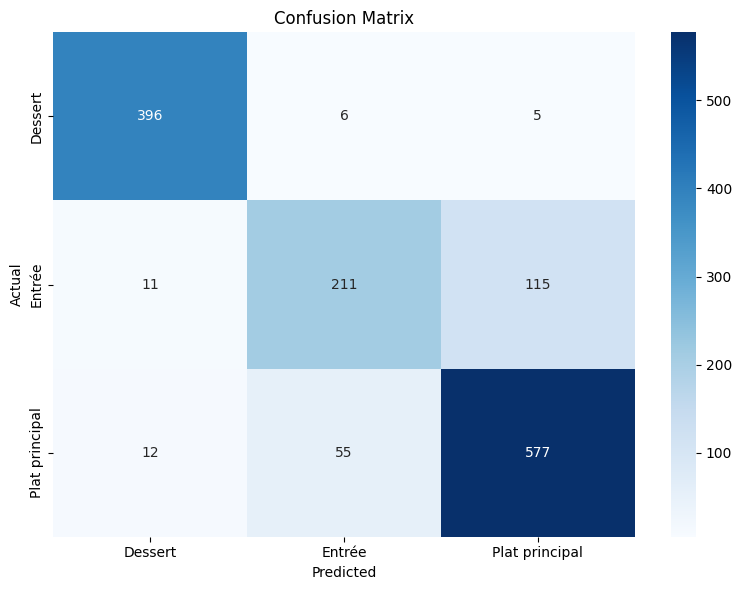

In [ ]:
from sklearn.metrics import accuracy_score, f1_score, classification_report

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Macro F1:", f1_score(y_test, y_pred, average="macro"))
print("Micro F1:", f1_score(y_test, y_pred, average="micro"))

print(classification_report(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred)
labels = sorted(set(y_test) | set(y_pred))

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.tight_layout()
plt.show()


In this run, we extended the previous approach by incorporating **additional structured features** alongside the TF-IDF representation, in order to integrate domain knowledge identified during the exploratory analysis.

#### Method description

* **Text features:** TF-IDF (n-grams 1–2) on `titre + recette`
* **Classifier:** Logistic Regression
* **Additional features:**

  * Title length (`titre_len`)
  * Recipe length (`recette_len`)
  * Number of ingredients (`num_ingredients`)
  * Sweet ingredient indicators (`sweet_score`)
  * Savory ingredient indicators (`savory_score`)

#### Motivation

The goal of this enriched model is to complement textual features with **high-level signals**:

* **Length features** (title and recipe length) aim to capture structural differences between recipe types.
* **Number of ingredients** may reflect recipe complexity and type (e.g., main dishes vs simpler preparations).
* **Sweet indicators** (e.g., *sucre*, *chocolat*, *vanille*) are expected to help identify dessert recipes.
* **Savory indicators** (e.g., *huile*, *viande*, *poulet*) are intended to capture signals typical of main dishes.

By combining **textual representations with handcrafted features**, this model aims to provide a richer description of each recipe and improve classification performance.

#### Results

| Metric   | Score |
| -------- | ----- |
| Accuracy | 0.853 |
| Macro-F1 | 0.837 |
| Micro-F1 | 0.853 |

#### Analysis

Contrary to expectations, the enriched model **does not improve performance** compared to Run 4. In fact, a slight decrease is observed across all metrics.

A detailed analysis shows that:

* **Dessert classification remains strong**, but slightly decreases.
* **Entrée classification degrades**, with recall dropping compared to Run 4.
* **Plat principal performance also slightly decreases**.

#### Interpretation

This result suggests that the additional features introduced do not provide significant new information beyond what is already captured by TF-IDF.

In particular:

* **Keyword-based features (e.g., sweet or savory indicators)** are largely redundant, as these words are already present in the text representation.
* **Structural features** (such as recipe length or number of ingredients) are weakly correlated with the target classes and introduce noise.
* Logistic Regression is sensitive to irrelevant or low-informative features, which can negatively impact performance.

#### Conclusion

These results highlight that:

* Carefully designed **textual features (TF-IDF with n-grams)** are already highly effective for this task.
* Adding additional features does not necessarily improve performance and may even degrade it if they are not sufficiently informative.

The best-performing model remains **Run 4**, which balances expressiveness and simplicity.


### Run6 (Bonus): FastText Model


Accuracy: 0.8587896253602305
Macro F1: 0.8498999225026623
Micro F1: 0.8587896253602305

Classification Report:

                precision    recall  f1-score   support

       Dessert       0.98      0.99      0.99       407
        Entrée       0.73      0.69      0.71       337
Plat principal       0.85      0.86      0.85       644

      accuracy                           0.86      1388
     macro avg       0.85      0.85      0.85      1388
  weighted avg       0.86      0.86      0.86      1388



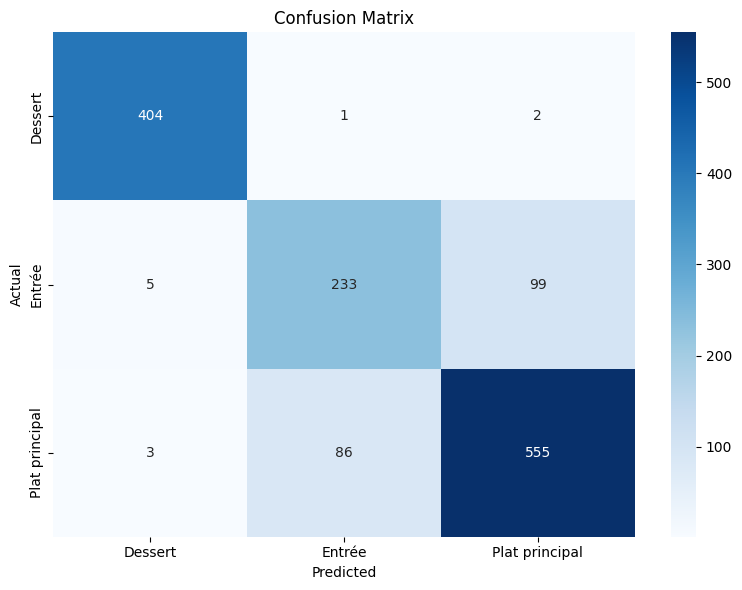

In [ ]:

import fasttext
import pandas as pd
import numpy as np
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix


df_train["text"] = (df_train["titre"].fillna("") + " " + df_train["recette"].fillna("")).str.replace("\n", " ", regex=False)
df_test["text"] = (df_test["titre"].fillna("") + " " + df_test["recette"].fillna("")).str.replace("\n", " ", regex=False)


def format_label(label):
    return "__label__" + label.replace(" ", "_")


def save_fasttext_file(df, filepath):
    with open(filepath, "w", encoding="utf-8") as f:
        for _, row in df.iterrows():
            label = format_label(row["type"])
            text = row["text"].strip()
            f.write(f"{label} {text}\n")

train_file = "fasttext_train.txt"
test_file = "fasttext_test.txt"

save_fasttext_file(df_train, train_file)
save_fasttext_file(df_test, test_file)


model = fasttext.train_supervised(
    input=train_file,
    lr=0.8,            # learning rate
    epoch=25,          # number of passes over training data
    wordNgrams=2,      # use unigrams + bigrams
    dim=100,           # embedding size
    loss="softmax",    # multi-class classification
    minn=2,            # min char ngram
    maxn=5,            # max char ngram
    verbose=2
)


y_test = df_test["type"].values

predictions = []
confidences = []

for text in df_test["text"]:
    labels, probs = model.predict([text], k=1)
    pred_label = labels[0][0].replace("__label__", "").replace("_", " ")
    predictions.append(pred_label)
    confidences.append(probs[0][0])

y_pred = np.array(predictions)

df_test["pred_fasttext"] = y_pred
df_test["confidence_fasttext"] = confidences


accuracy = accuracy_score(y_test, y_pred)
macro_f1 = f1_score(y_test, y_pred, average="macro")
micro_f1 = f1_score(y_test, y_pred, average="micro")

print("Accuracy:", accuracy)
print("Macro F1:", macro_f1)
print("Micro F1:", micro_f1)

print("\nClassification Report:\n")
print(classification_report(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred)
labels = sorted(set(y_test) | set(y_pred))

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.tight_layout()
plt.show()


As a bonus experiment, we implemented a **FastText-based classifier**, which represents text using **word embeddings and subword information**.

#### Method description

* **Input:** `titre + recette`
* **Model:** FastText supervised classifier
* **Configuration:** word n-grams (`wordNgrams=2`) and subword modeling

#### Results

| Metric   | Score |
| -------- | ----- |
| Accuracy | 0.859 |
| Macro-F1 | 0.850 |
| Micro-F1 | 0.859 |

#### Analysis

The FastText model achieves solid performance, outperforming the enriched feature-based model (Run 5), but remaining below the performance of the TF-IDF + Logistic Regression model (Run 4).

* **Dessert classification remains nearly perfect**, confirming that this class is highly separable.
* **Entrée classification improves compared to simpler models**, but does not reach the performance of Run 4.
* **Plat principal performance is slightly lower** than in Run 4.

#### Interpretation

FastText captures **semantic relationships and subword information**, which helps generalization. However, in this task, classification relies heavily on **specific lexical cues** (e.g., *sucre*, *chocolat*, *poulet*, *soupe*).

As a result:

* TF-IDF-based models are more effective at leveraging **exact word occurrences**.
* FastText provides a more **general representation**, but with slightly less discriminative power for this dataset.

#### Conclusion

This experiment shows that **embedding-based approaches are not always superior to simpler models**, especially when the task depends on highly discriminative vocabulary.

The best-performing model remains **TF-IDF + Logistic Regression (Run 4)**.


## Global Conclusion

In this project, we explored several approaches for the classification of cooking recipes into three categories: **Entrée**, **Plat principal**, and **Dessert**.

We followed a progressive experimental methodology, starting from simple baselines and gradually introducing more sophisticated models and features.

---

### Summary of approaches

* **Baselines** (random and majority class) provided reference points, highlighting the difficulty of the task and the impact of class imbalance.
* **Naive Bayes with TF-IDF (Run 3)** demonstrated that lexical information is highly informative, achieving strong performance, especially for the Dessert class.
* **Logistic Regression with n-grams (Run 4)** significantly improved results by capturing word combinations and modeling feature interactions. This model achieved the best overall performance.
* **Enriched model (Run 5)** introduced additional handcrafted features (length, ingredient counts, keyword indicators), but did not improve performance, showing that not all features are beneficial.
* **FastText (Run 6, bonus)** explored an embedding-based approach, providing competitive results but remaining slightly below the best TF-IDF model.

---

### Key findings

Several important insights emerged from this study:

* **Lexical features are highly discriminative**: words such as *sucre*, *chocolat*, *poulet*, and *soupe* provide strong signals for classification.
* **Dessert recipes are the easiest to classify**, due to their distinctive vocabulary.
* The main difficulty lies in distinguishing **Entrée from Plat principal**, as these classes share many ingredients and cooking terms.
* **Model choice matters**: discriminative models such as Logistic Regression outperform Naive Bayes by better handling overlapping vocabularies.
* **Feature engineering must be relevant**: adding weak or redundant features can degrade performance rather than improve it.
* **Simple models can outperform more complex ones**: TF-IDF combined with Logistic Regression proved more effective than embedding-based methods like FastText for this task.

---

### Final conclusion

The best-performing approach is **TF-IDF with n-grams combined with Logistic Regression (Run 4)**, which provides an effective balance between simplicity, interpretability, and performance.

This project highlights that, for structured text classification tasks with strong lexical cues, **well-designed classical methods remain highly competitive**, and sometimes superior, to more complex approaches.

---

### Perspectives

Future improvements could focus on:

* Better handling of ambiguity between **Entrée and Plat principal**
* More advanced feature engineering (e.g., refined ingredient extraction)
* Fine-tuning transformer-based models such as CamemBERT

Overall, this work demonstrates the importance of combining **data analysis, model comparison, and critical reasoning** to build effective NLP systems.
